This notebook ('diann_peptide_quants_at_rts.ipynb') reads and filters the main report from DIANN output (report.parquet), selects runs for defined conditions, and analyzes peptide quantity (Ms1.Apex.Area) across retention time, aligning each condition's retention time axis to zero using the same strategy as the peptide-identification-vs-RT analysis.
Results are exported as individual .csv files (peptide-level and peptide-replicate-level quantities, RT alignment shift values, and binned mean/SD/SEM quantities) together with scatter+LOWESS and binned mean±SEM envelope plots, separately for forward and reverse flush modes.

**Workflow overview:**

1. **Setup** – Import packages, set working directory, import custom `diann_main_report_filtering` and `retention_time_stability_stats` modules, enable autoreload, configure pandas display options.
2. **Define paths** – Set `input_dir` / `output_dir` for the dataset to process.
3. **Load report** – Read DIA-NN's `report.parquet` into a pandas DataFrame.
4. **FDR filtering** – Sequentially filter the main report at 1% precursor Q.Value (run-specific and global) and 1% global protein group Q.Value, plus a lenient Quantity.Quality cutoff (≥ 0.5).
5. **Run selection** – Define forward and reverse flush run lists per condition (pepmap, nanoshield_tht021_flip, direct_injection) and subset the filtered report into `main_report_pd_fil_for` / `main_report_pd_fil_rev`.
6. **Condition assignment & completeness filtering** – Map acquisition dates to condition names, then retain only peptides quantitatively complete in all replicates within their own condition.
7. **Build quantity tables** – Aggregate to a peptide-level table (mean RT and quantity per peptide per condition, for scatter) and a peptide×replicate table (per-replicate quantity, for SD/SEM).
8. **RT zero-alignment** – Derive a per-condition constant RT shift (same bin-occupancy strategy as the peptide-ID-vs-RT notebook) and apply it to both tables.
9. **Binning** – Re-bin the globally shifted RT range into `N_RT_BINS` equal-width bins and compute mean, SD, and SEM of log10(quantity) per condition per bin, pooled across replicates and peptides.
10. **Export & plot** – For each flush mode (forward, reverse), export peptide-level, peptide-replicate-level, shift-value, and binned quantity `.csv` files; generate and save a raw scatter+LOWESS plot and a binned mean±SEM envelope plot (PNG and SVG) per flush mode.

In [1]:
# import relevant packages
import sys
import os
import inspect
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from textwrap import dedent

# change working direction - point to where your notebooks (.ipynb) and python files (.py) are placed
new_cwd = Path("Z:/user/Dennis/trap_column_test/manuscript/diann_processing/jupyter_notebooks/github/")
os.chdir(new_cwd)
# verify new working directory
print("Current working directory:\n",os.getcwd())

# import custom functions
import diann_main_report_filtering as diann_filter
import retention_time_stability_stats as rts

# auto reload of imported packages
%load_ext autoreload
%autoreload 2

# check where python is looking for path to resolve imports and where it actually loaded the packages from
print(f"This is where python is looking for packages:\n{sys.path}\n")

# change display settings for pandas dataframes
pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)
pd.set_option("display.max_colwidth", None)

# set to back to default if needed
#pd.reset_option("display.max_columns")
#pd.reset_option("display.max_rows")
    
# check current working directory of this notebook
print("Current working directory:")
!pwd

Current working directory:
 Z:\user\Dennis\trap_column_test\manuscript\diann_processing\jupyter_notebooks\github
This is where python is looking for packages:
['C:\\Users\\dennis.dannecker\\AppData\\Local\\anaconda3\\envs\\trap_column_test\\python313.zip', 'C:\\Users\\dennis.dannecker\\AppData\\Local\\anaconda3\\envs\\trap_column_test\\DLLs', 'C:\\Users\\dennis.dannecker\\AppData\\Local\\anaconda3\\envs\\trap_column_test\\Lib', 'C:\\Users\\dennis.dannecker\\AppData\\Local\\anaconda3\\envs\\trap_column_test', '', 'C:\\Users\\dennis.dannecker\\AppData\\Local\\anaconda3\\envs\\trap_column_test\\Lib\\site-packages', 'C:\\Users\\dennis.dannecker\\AppData\\Local\\anaconda3\\envs\\trap_column_test\\Lib\\site-packages\\win32', 'C:\\Users\\dennis.dannecker\\AppData\\Local\\anaconda3\\envs\\trap_column_test\\Lib\\site-packages\\win32\\lib', 'C:\\Users\\dennis.dannecker\\AppData\\Local\\anaconda3\\envs\\trap_column_test\\Lib\\site-packages\\Pythonwin']

Current working directory:
/z/user/Dennis/t

In [2]:
# define input and output directories for each acquired dataset

input_dir = Path("Z:/user/Dennis/trap_column_test/manuscript/diann_processing/dataset_g_combined/")
output_dir = Path("Z:/user/Dennis/trap_column_test/manuscript/diann_processing/dataset_g_combined/github_test/peptide_quants_at_rts/")

In [3]:
# read dianns main output parquet file as a pandas dataframe

# define input file name
input_file_name = "report.parquet"
# define input file path
input_file_path = input_dir / input_file_name
# read parquet file as pd dataframe
main_report_pd = pd.read_parquet(input_file_path, engine='pyarrow')
print("DIANN's parquet file was read in as a pandas dataframe.")

DIANN's parquet file was read in as a pandas dataframe.


In [4]:
# perform basic FDR filtering of loaded main report, "main_report_pd"

# filters sequentially, overwriting the variable to save memory
main_report_pd_fil = diann_filter.filter_dataframe(df=main_report_pd, column="Q.Value", cutoff=0.01, smaller_than=True, filter_proteotypic=False) # default precursor filtering at 1%, run-specific
main_report_pd_fil = diann_filter.filter_dataframe(df=main_report_pd_fil, column="Global.Q.Value", cutoff=0.01, smaller_than=True, filter_proteotypic=False) # precursor filtering at 1%, global
main_report_pd_fil = diann_filter.filter_dataframe(df=main_report_pd_fil, column="Global.PG.Q.Value", cutoff=0.01, smaller_than=True, filter_proteotypic=False) # protein group filtering at 1%, global
# lenient, retain the vast majority of IDs, drop only clearly bad ones - quality of precursor quantity, is it trustworthy
main_report_pd_fil = diann_filter.filter_dataframe(df=main_report_pd_fil, column="Quantity.Quality", cutoff=0.5, smaller_than=False, filter_proteotypic=False)
# reset index after filtering to maintain a clean sequence
main_report_pd_fil.reset_index(drop=True, inplace=True)
print("Dataframe was filtered successfully")

Dataframe was filtered successfully


In [5]:
# higher level conditions and run selection

# define selected runs
run_sel_for = [
  # pepmap - forward
  "20260911_N2A1_TH103_DD_THIDTrapTestG_pep_QCdia250_for_1",
  "20260911_N2A1_TH103_DD_THIDTrapTestG_pep_QCdia250_for_2",
  "20260911_N2A1_TH103_DD_THIDTrapTestG_pep_QCdia250_for_3",
  "20260911_N2A1_TH103_DD_THIDTrapTestG_pep_QCdia250_for_4",
  "20260911_N2A1_TH103_DD_THIDTrapTestG_pep_QCdia250_for_5",
  "20260911_N2A1_TH103_DD_THIDTrapTestG_pep_QCdia250_for_6",
  # nanoshield tht021 flipped - forward
  "20260914_N2A1_TH103_DD_THIDTrapTestG_cc1_tht021_flip_QCdia250_for_1",
  "20260914_N2A1_TH103_DD_THIDTrapTestG_cc1_tht021_flip_QCdia250_for_2",
  "20260914_N2A1_TH103_DD_THIDTrapTestG_cc1_tht021_flip_QCdia250_for_3",
  "20260914_N2A1_TH103_DD_THIDTrapTestG_cc1_tht021_flip_QCdia250_for_4",
  "20260914_N2A1_TH103_DD_THIDTrapTestG_cc1_tht021_flip_QCdia250_for_5",
  "20260914_N2A1_TH103_DD_THIDTrapTestG_cc1_tht021_flip_QCdia250_for_6",
  # direct injection
  "20260916_N2A1_TH103_DD_THIDTrapTestG_cc1_di_QCdia250_1",
  "20260916_N2A1_TH103_DD_THIDTrapTestG_cc1_di_QCdia250_2",
  "20260916_N2A1_TH103_DD_THIDTrapTestG_cc1_di_QCdia250_3",
  "20260916_N2A1_TH103_DD_THIDTrapTestG_cc1_di_QCdia250_4",
  "20260916_N2A1_TH103_DD_THIDTrapTestG_cc1_di_QCdia250_5",
  "20260916_N2A1_TH103_DD_THIDTrapTestG_cc1_di_QCdia250_6", 
]

run_sel_rev = [
  # pepmap - reverse
  "20260911_N2A1_TH103_DD_THIDTrapTestG_pep_QCdia250_rev_1",
  "20260911_N2A1_TH103_DD_THIDTrapTestG_pep_QCdia250_rev_2",
  "20260911_N2A1_TH103_DD_THIDTrapTestG_pep_QCdia250_rev_3",
  "20260911_N2A1_TH103_DD_THIDTrapTestG_pep_QCdia250_rev_4",
  "20260911_N2A1_TH103_DD_THIDTrapTestG_pep_QCdia250_rev_5",
  "20260911_N2A1_TH103_DD_THIDTrapTestG_pep_QCdia250_rev_6",
  # nanoshield tht021 flipped - reverse
  "20260914_N2A1_TH103_DD_THIDTrapTestG_cc1_tht021_flip_QCdia250_rev_1",
  "20260914_N2A1_TH103_DD_THIDTrapTestG_cc1_tht021_flip_QCdia250_rev_2",
  "20260914_N2A1_TH103_DD_THIDTrapTestG_cc1_tht021_flip_QCdia250_rev_3",
  "20260914_N2A1_TH103_DD_THIDTrapTestG_cc1_tht021_flip_QCdia250_rev_4",
  "20260914_N2A1_TH103_DD_THIDTrapTestG_cc1_tht021_flip_QCdia250_rev_5",
  "20260914_N2A1_TH103_DD_THIDTrapTestG_cc1_tht021_flip_QCdia250_rev_6",
  # direct injection
  "20260916_N2A1_TH103_DD_THIDTrapTestG_cc1_di_QCdia250_1",
  "20260916_N2A1_TH103_DD_THIDTrapTestG_cc1_di_QCdia250_2",
  "20260916_N2A1_TH103_DD_THIDTrapTestG_cc1_di_QCdia250_3",
  "20260916_N2A1_TH103_DD_THIDTrapTestG_cc1_di_QCdia250_4",
  "20260916_N2A1_TH103_DD_THIDTrapTestG_cc1_di_QCdia250_5",
  "20260916_N2A1_TH103_DD_THIDTrapTestG_cc1_di_QCdia250_6", 
]

# select runs from main report using exact matching for "Run" name - main_report_pd_fil_for is main dataframe used for all analyses below - forward
main_report_pd_fil_for = main_report_pd_fil[main_report_pd_fil["Run"].isin(run_sel_for)].copy()
print("Selection is done - forward")
# select runs from main report using exact matching for "Run" name - main_report_pd_fil_rev is main dataframe used for all analyses below - reverse
main_report_pd_fil_rev = main_report_pd_fil[main_report_pd_fil["Run"].isin(run_sel_rev)].copy()
print("Selection is done - reverse")

Selection is done - forward
Selection is done - reverse



=== [forward] ===
  [pepmap] peptides complete in all replicates: 10623
  [nanoshield_tht021_flip] peptides complete in all replicates: 16847
  [direct_injection] peptides complete in all replicates: 25746
  RT zero-alignment 'pepmap': first occupied bin left edge = 2.525 min -> shift = -2.525 min
  RT zero-alignment 'nanoshield_tht021_flip': first occupied bin left edge = 1.586 min -> shift = -1.586 min
  RT zero-alignment 'direct_injection': first occupied bin left edge = 0.563 min -> shift = -0.563 min
Saved → Z:\user\Dennis\trap_column_test\manuscript\diann_processing\dataset_g_combined\github_test\peptide_quants_at_rts\peptide_quantity_vs_rt_scatter_forward.png
Saved → Z:\user\Dennis\trap_column_test\manuscript\diann_processing\dataset_g_combined\github_test\peptide_quants_at_rts\peptide_quantity_vs_rt_scatter_forward.svg


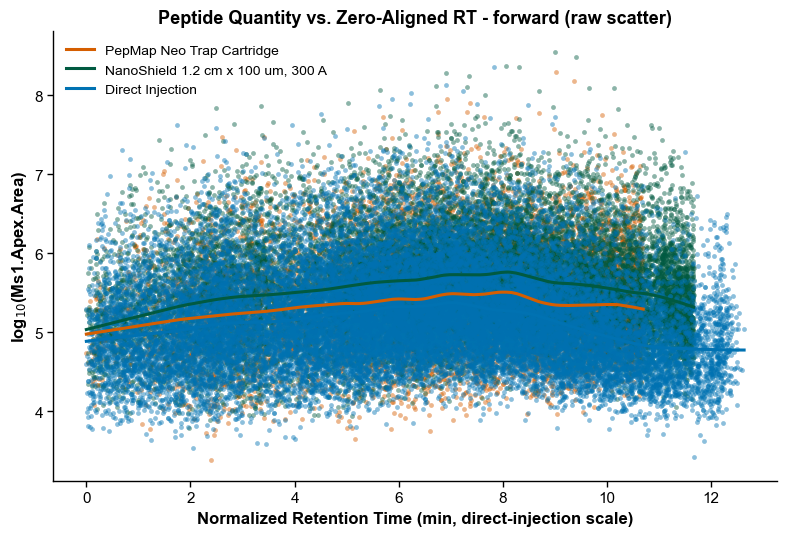

[forward] Binning quantities into 100 RT bins (pooled replicate values)...
Saved → Z:\user\Dennis\trap_column_test\manuscript\diann_processing\dataset_g_combined\github_test\peptide_quants_at_rts\peptide_quantity_vs_rt_binned_forward_100_bins.png
Saved → Z:\user\Dennis\trap_column_test\manuscript\diann_processing\dataset_g_combined\github_test\peptide_quants_at_rts\peptide_quantity_vs_rt_binned_forward_100_bins.svg


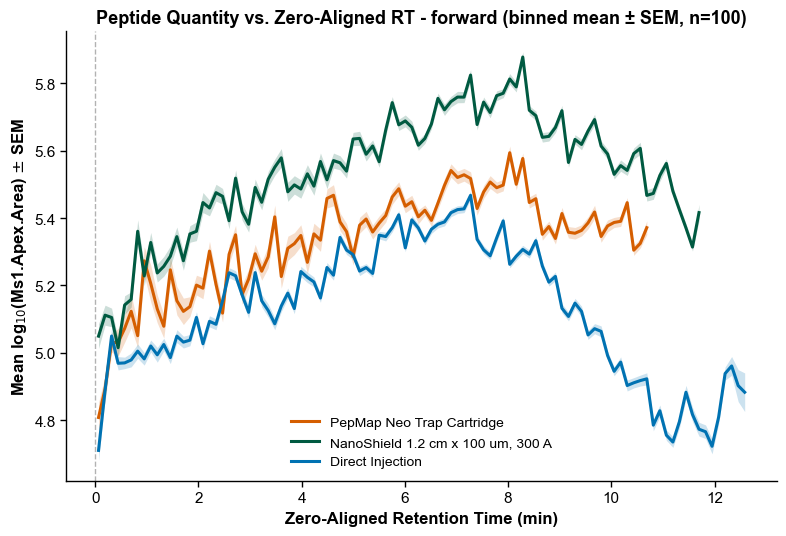


=== [reverse] ===
  [pepmap] peptides complete in all replicates: 19116
  [nanoshield_tht021_flip] peptides complete in all replicates: 25377
  [direct_injection] peptides complete in all replicates: 25746
  RT zero-alignment 'pepmap': first occupied bin left edge = 2.525 min -> shift = -2.525 min
  RT zero-alignment 'nanoshield_tht021_flip': first occupied bin left edge = 1.589 min -> shift = -1.589 min
  RT zero-alignment 'direct_injection': first occupied bin left edge = 0.563 min -> shift = -0.563 min
Saved → Z:\user\Dennis\trap_column_test\manuscript\diann_processing\dataset_g_combined\github_test\peptide_quants_at_rts\peptide_quantity_vs_rt_scatter_reverse.png
Saved → Z:\user\Dennis\trap_column_test\manuscript\diann_processing\dataset_g_combined\github_test\peptide_quants_at_rts\peptide_quantity_vs_rt_scatter_reverse.svg


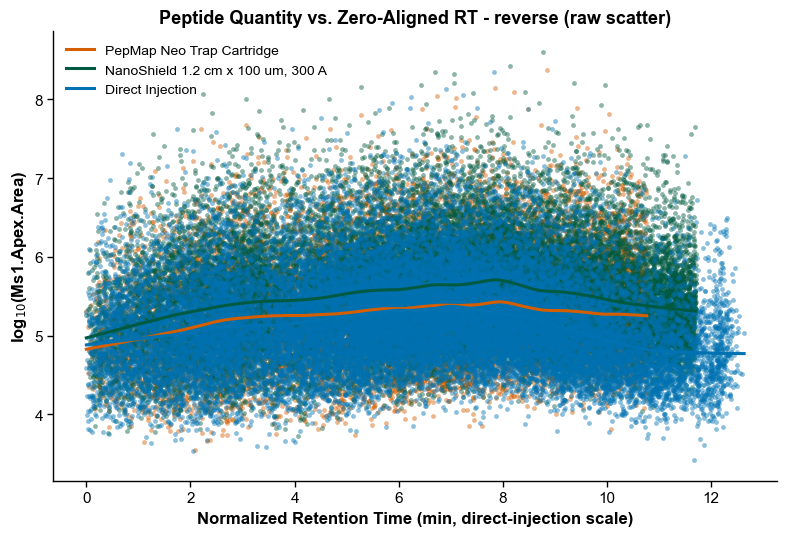

[reverse] Binning quantities into 100 RT bins (pooled replicate values)...
Saved → Z:\user\Dennis\trap_column_test\manuscript\diann_processing\dataset_g_combined\github_test\peptide_quants_at_rts\peptide_quantity_vs_rt_binned_reverse_100_bins.png
Saved → Z:\user\Dennis\trap_column_test\manuscript\diann_processing\dataset_g_combined\github_test\peptide_quants_at_rts\peptide_quantity_vs_rt_binned_reverse_100_bins.svg


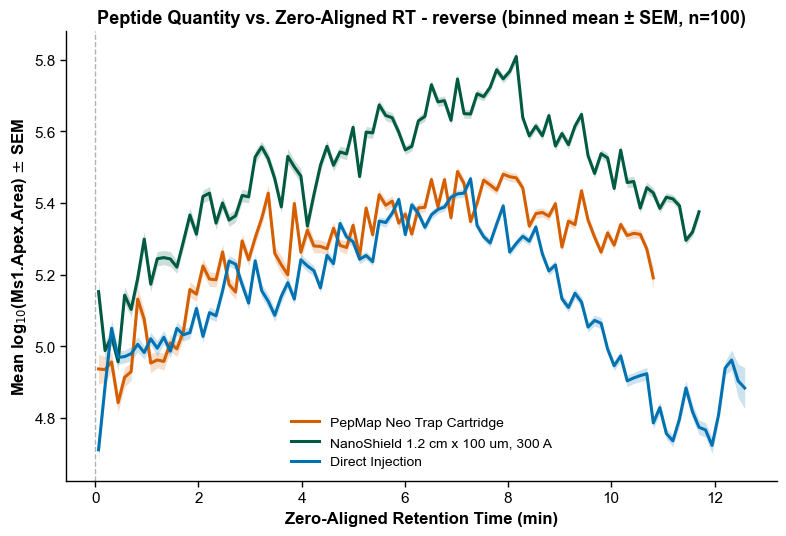

In [6]:
# ══════════════════════════════════════════════════════════════════════════════
# PEPTIDE QUANTITY (Ms1.Apex.Area) vs. RT — per-condition completeness,
# RT ZERO-ALIGNMENT (same strategy as identified-peptides-vs-RT),
# raw scatter + LOWESS, and binned mean ± SE envelope (replicate-level SE)
# ══════════════════════════════════════════════════════════════════════════════

conditions = ["pepmap", "nanoshield_tht021_flip", "direct_injection"]
N_RT_BINS = 100  # user-controlled, default 100

date_to_condition = {
    "20260911": "pepmap",
    "20260914": "nanoshield_tht021_flip",
    "20260916": "direct_injection",
}


def fit_rt_zero_alignment_shift(rt_values, n_bins=N_RT_BINS):
    """
    Bin a condition's own (raw) peptide RTs into n_bins bins over its own RT
    range, find the left edge of the first bin containing at least one
    identified peptide, and return the shift that moves that edge to RT = 0
    (shift = -left_edge). Same logic as the identified-peptides-vs-RT cell.
    """
    rt_min = rt_values.min()
    rt_max = rt_values.max()
    bin_edges = np.linspace(rt_min, rt_max, n_bins + 1)
    bin_idx = pd.cut(rt_values, bins=bin_edges, include_lowest=True, labels=False)
    occupied_bins = np.sort(pd.unique(bin_idx[~pd.isna(bin_idx)].astype(int)))
    first_occupied_bin = occupied_bins[0]
    first_bin_left_edge = bin_edges[first_occupied_bin]
    shift = -first_bin_left_edge
    return shift, first_bin_left_edge


def build_peptide_run_quantity(df_complete, seq_col="Stripped.Sequence",
                                condition_col="Condition", run_col="Run",
                                rt_col="RT", quant_col="Ms1.Apex.Area"):
    """
    Collapse precursor rows (charge states) to one quantity value per
    (Condition, peptide, Run) — i.e. one value per replicate — preserving
    replicate-to-replicate variability for later SD and SEM computation.
    """
    return (
        df_complete.groupby([condition_col, seq_col, run_col])
        .agg(**{rt_col: (rt_col, "mean"), quant_col: (quant_col, "mean")})
        .reset_index()
    )


def build_peptide_quantity_tables(df, conditions, n_bins=N_RT_BINS,
                                   seq_col="Stripped.Sequence",
                                   condition_col="Condition",
                                   run_col="Run", rt_col="RT",
                                   quant_col="Ms1.Apex.Area"):
    """
    Build both the peptide-level table (for scatter) and the
    peptide x replicate table (for binned mean+SD), each independently
    filtered to quantitative completeness WITHIN its own condition only
    (no cross-condition intersection), then RT ZERO-ALIGNED per condition
    using a constant shift derived from bin occupancy (same strategy as the
    identified-peptides-vs-RT analysis).

    Returns
    -------
    peptide_level : pd.DataFrame
        [condition, peptide, RT, quantity, RT_Shifted] — one row per
        (condition, peptide).
    peptide_run_level : pd.DataFrame
        [condition, peptide, run, RT, quantity, RT_Shifted] — one row per
        (condition, peptide, run).
    shifts, first_edges : dict
        Per-condition shift values and first-occupied-bin left edges.
    """
    # 1. per-condition completeness filter (no cross-condition intersection)
    df_complete = rts.filter_peptides_complete_within_condition(
        df, seq_col=seq_col, condition_col=condition_col,
        run_col=run_col, quant_col=quant_col,
    )

    # report total peptides retained per condition
    for cond in conditions:
        n_pep = df_complete.loc[df_complete[condition_col] == cond, seq_col].nunique()
        print(f"  [{cond}] peptides complete in all replicates: {n_pep}")

    # 2. peptide-level aggregation (mean RT, mean quantity) — for scatter
    #    RT is the representative RT used to derive the zero-alignment shift,
    #    calculated BEFORE shifting (mean across all observations - replicates
    #    and charge states - of that peptide within the condition)
    peptide_level = (
        df_complete.groupby([condition_col, seq_col])
        .agg(**{rt_col: (rt_col, "mean"), quant_col: (quant_col, "mean")})
        .reset_index()
    )

    # 3. peptide x replicate aggregation — for binned SD
    peptide_run_level = build_peptide_run_quantity(
        df_complete, seq_col=seq_col, condition_col=condition_col,
        run_col=run_col, rt_col=rt_col, quant_col=quant_col,
    )

    # 4. RT zero-alignment: derive a constant per-condition shift from the
    #    peptide-level representative RTs (same approach as
    #    identified-peptides-vs-RT), then apply that SAME shift to both the
    #    peptide-level and peptide-replicate-level tables
    peptide_level["RT_Shifted"] = peptide_level[rt_col]
    peptide_run_level["RT_Shifted"] = peptide_run_level[rt_col]

    shifts = {}
    first_edges = {}
    for cond in conditions:
        mask_pl = peptide_level[condition_col] == cond
        rt_values = peptide_level.loc[mask_pl, rt_col]
        shift, first_bin_left_edge = fit_rt_zero_alignment_shift(rt_values, n_bins=n_bins)
        shifts[cond] = shift
        first_edges[cond] = first_bin_left_edge
        print(f"  RT zero-alignment '{cond}': first occupied bin left edge = "
              f"{first_bin_left_edge:.3f} min -> shift = {shift:+.3f} min")

        peptide_level.loc[mask_pl, "RT_Shifted"] = rt_values + shift

        mask_pr = peptide_run_level[condition_col] == cond
        peptide_run_level.loc[mask_pr, "RT_Shifted"] = peptide_run_level.loc[mask_pr, rt_col] + shift

    return peptide_level, peptide_run_level, shifts, first_edges


def bin_quantity_by_rt_pooled(peptide_run_level, conditions, n_bins=100,
                               quant_col="Ms1.Apex.Area",
                               rt_col="RT_Shifted",
                               condition_col="Condition"):
    """
    Bin RT_Shifted into n_bins equal-width bins spanning the GLOBAL shifted-RT
    range across all conditions (so bins are directly comparable across
    conditions, same as identified-peptides-vs-RT), and within each
    (condition, bin) compute mean, SD and SEM of log10(quantity) POOLED
    ACROSS REPLICATES AND PEPTIDES (i.e. using the peptide x replicate table,
    not peptide means).
    """
    df = peptide_run_level.copy()
    df["log10_Quantity"] = np.log10(df[quant_col])

    rt_min, rt_max = df[rt_col].min(), df[rt_col].max()
    bin_edges = np.linspace(rt_min, rt_max, n_bins + 1)
    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
    df["RT_bin"] = pd.cut(df[rt_col], bins=bin_edges, include_lowest=True, labels=False)

    rows = []
    for cond in conditions:
        sub = df[df[condition_col] == cond]
        grouped = sub.groupby("RT_bin")["log10_Quantity"]
        means = grouped.mean()
        sds = grouped.std()
        ns = grouped.count()
        sems = sds / np.sqrt(ns)
        n_peptides = sub.groupby("RT_bin")["Stripped.Sequence"].nunique()

        for bin_idx in range(n_bins):
            rows.append({
                condition_col: cond,
                "RT_bin_center": bin_centers[bin_idx],
                "mean_log10": means.get(bin_idx, np.nan),
                "sd_log10": sds.get(bin_idx, np.nan),
                "sem_log10": sems.get(bin_idx, np.nan),
                "n_values": ns.get(bin_idx, 0),
                "n_peptides": n_peptides.get(bin_idx, 0),
            })

    return pd.DataFrame(rows)


def plot_quantity_binned_envelope(binned_df, conditions, error_type="sem", title=None):
    """
    One mean log10(quantity) line per condition across RT bins, with a
    shaded ±SEM envelope computed from pooled replicate values.
    """
    err_col = "sem_log10" if error_type == "sem" else "sd_log10"

    fig, ax = plt.subplots(figsize=(8, 5.5))
    for cond in conditions:
        sub = binned_df[binned_df["Condition"] == cond].sort_values("RT_bin_center")
        sub = sub.dropna(subset=["mean_log10"])
        x = sub["RT_bin_center"].values
        y = sub["mean_log10"].values
        err = sub[err_col].values

        ax.plot(x, y, color=rts.get_color(cond), linewidth=2.2, label=rts.get_label(cond))
        ax.fill_between(x, y - err, y + err, color=rts.get_color(cond), alpha=0.2, linewidth=0)

    ax.axvline(0, color="gray", linestyle="--", linewidth=1, alpha=0.6)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.set_facecolor("white")
    fig.patch.set_facecolor("white")
    ax.grid(False)
    ax.set_xlabel("Zero-Aligned Retention Time (min)", fontsize=12, fontweight="semibold")
    ax.set_ylabel(r"Mean log$_{10}$(Ms1.Apex.Area) $\pm$ " + error_type.upper(), fontsize=12, fontweight="semibold")
    if title:
        ax.set_title(title, fontsize=13, fontweight="bold")
    ax.legend(frameon=False, fontsize=10)
    fig.tight_layout()
    return fig


# ── main loop: forward / reverse ────────────────────────────────────────────
for flush_label, df_source in [
    ("forward", main_report_pd_fil_for),
    ("reverse", main_report_pd_fil_rev),
]:
    print(f"\n=== [{flush_label}] ===")
    main_report_pd_fil_quant_pep = df_source.copy()
    main_report_pd_fil_quant_pep["Condition"] = (
        main_report_pd_fil_quant_pep["Run"].astype(str).str[:8].map(date_to_condition)
    )
    main_report_pd_fil_quant_pep = main_report_pd_fil_quant_pep[
        main_report_pd_fil_quant_pep["Condition"].isin(conditions)
    ].copy()

    peptide_level, peptide_run_level, shifts, first_edges = build_peptide_quantity_tables(
        main_report_pd_fil_quant_pep,
        conditions=conditions,
        n_bins=N_RT_BINS,
        seq_col="Stripped.Sequence",
        condition_col="Condition",
        run_col="Run",
        rt_col="RT",
        quant_col="Ms1.Apex.Area",
    )

    # ── export raw data ─────────────────────────────────────────────────────
    peptide_level.to_csv(output_dir / f"peptide_quantity_vs_rt_peptide_level_{flush_label}_zero_aligned_rt.csv", index=False)
    peptide_run_level.to_csv(output_dir / f"peptide_quantity_vs_rt_peptide_replicate_level_{flush_label}_zero_aligned_rt.csv", index=False)
    pd.DataFrame({
        "Condition": list(shifts.keys()),
        "First_Occupied_Bin_Left_Edge_Min": [first_edges[c] for c in shifts],
        "RT_Shift_Min": [shifts[c] for c in shifts],
    }).to_csv(output_dir / f"peptide_quantity_rt_zero_alignment_shift_values_{flush_label}.csv", index=False)

    # (a) raw scatter + LOWESS (peptide-level table, unchanged approach,
    #     now using zero-aligned RT)
    fig_scatter = rts.plot_quantity_vs_rt(
        peptide_level,
        conditions=conditions,
        quant_col="Ms1.Apex.Area",
        rt_col="RT_Shifted",
        title=f"Peptide Quantity vs. Zero-Aligned RT - {flush_label} (raw scatter)",
    )
    for ext in ("png", "svg"):
        out_path = output_dir / f"peptide_quantity_vs_rt_scatter_{flush_label}.{ext}"
        fig_scatter.savefig(out_path, dpi=600 if ext == "png" else None, bbox_inches="tight")
        print(f"Saved → {out_path}")
    plt.show()

    # (b) RT-binned mean ± SD envelope (pooled replicate-level values,
    #     re-binned on the global zero-aligned RT range)
    print(f"[{flush_label}] Binning quantities into {N_RT_BINS} RT bins (pooled replicate values)...")
    binned_quant = bin_quantity_by_rt_pooled(
        peptide_run_level,
        conditions=conditions,
        n_bins=N_RT_BINS,
        quant_col="Ms1.Apex.Area",
        rt_col="RT_Shifted",
        condition_col="Condition",
    )
    binned_quant.to_csv(output_dir / f"peptide_quantity_vs_rt_binned_{flush_label}_{N_RT_BINS}_bins_zero_aligned_rt.csv", index=False)

    fig_binned = plot_quantity_binned_envelope(
        binned_quant,
        conditions=conditions,
        error_type="sem",
        title=f"Peptide Quantity vs. Zero-Aligned RT - {flush_label} (binned mean ± SEM, n={N_RT_BINS})",
    )
    for ext in ("png", "svg"):
        out_path = output_dir / f"peptide_quantity_vs_rt_binned_{flush_label}_{N_RT_BINS}_bins.{ext}"
        fig_binned.savefig(out_path, dpi=600 if ext == "png" else None, bbox_inches="tight")
        print(f"Saved → {out_path}")
    plt.show()